In [1]:
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Train Shape:", train.shape)
print("Test Shape:", test.shape)

print("\nTrain Info:")
train.info()

print("\nMissing Values:")
print(train.isnull().sum().sort_values(ascending=False).head(20))

print("\nColumns:")
print(train.columns.tolist())

Train Shape: (1460, 81)
Test Shape: (1459, 80)

Train Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   objec

In [2]:
target = "SalePrice"

X = train.drop(columns=[target])
y = train[target]

print("X Shape:", X.shape)
print("y Shape:", y.shape)
print("\nTarget Statistics:")
print(y.describe())

X Shape: (1460, 80)
y Shape: (1460,)

Target Statistics:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [3]:
numeric_features = X.select_dtypes(include=["int64", "float64"]).columns
categorical_features = X.select_dtypes(include=["object"]).columns

print("Numerical Features:", len(numeric_features))
print("Categorical Features:", len(categorical_features))

print("\nNumerical:")
print(numeric_features.tolist())

print("\nCategorical:")
print(categorical_features.tolist())

Numerical Features: 37
Categorical Features: 43

Numerical:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']

Categorical:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Fu

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_val.shape)
print(y_train.shape)
print(y_val.shape)

(1168, 80)
(292, 80)
(1168,)
(292,)


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def create_preprocessor(numeric_features, categorical_features):

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

In [9]:
preprocessor = create_preprocessor(
    numeric_features,
    categorical_features
)

print("Preprocessor created")

Preprocessor created


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

def create_model_pipeline(model):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

In [11]:
models = {
    "Linear Regression": create_model_pipeline(LinearRegression()),
    "Ridge": create_model_pipeline(Ridge()),
    "Lasso": create_model_pipeline(Lasso()),
    "Elastic Net": create_model_pipeline(ElasticNet())
}

print(models.keys())

dict_keys(['Linear Regression', 'Ridge', 'Lasso', 'Elastic Net'])


In [12]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge

polynomial_model = Pipeline([
    ("preprocessor", preprocessor),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("model", Ridge(alpha=10))
])

models["Polynomial Regression"] = polynomial_model

print(models.keys())

dict_keys(['Linear Regression', 'Ridge', 'Lasso', 'Elastic Net', 'Polynomial Regression'])


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def evaluate_models(models, X_train, X_val, y_train, y_val):

    results = []

    for name, model in models.items():

        model.fit(X_train, y_train)
        predictions = model.predict(X_val)

        mae = mean_absolute_error(y_val, predictions)
        rmse = np.sqrt(mean_squared_error(y_val, predictions))
        r2 = r2_score(y_val, predictions)

        results.append({
            "Model": name,
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

    return pd.DataFrame(results).sort_values("RMSE")

In [14]:
results = evaluate_models(
    models,
    X_train,
    X_val,
    y_train,
    y_val
)

results

,Model,MAE,RMSE,R2
2,Lasso,17917.289289,28238.394539,0.896040
0,Linear Regression,18284.677599,29476.184616,0.886726
1,Ridge,19006.271311,29844.251463,0.883880
4,Polynomial Regression,20151.367851,30538.342329,0.878416
3,Elastic Net,20197.298252,36296.642842,0.828241


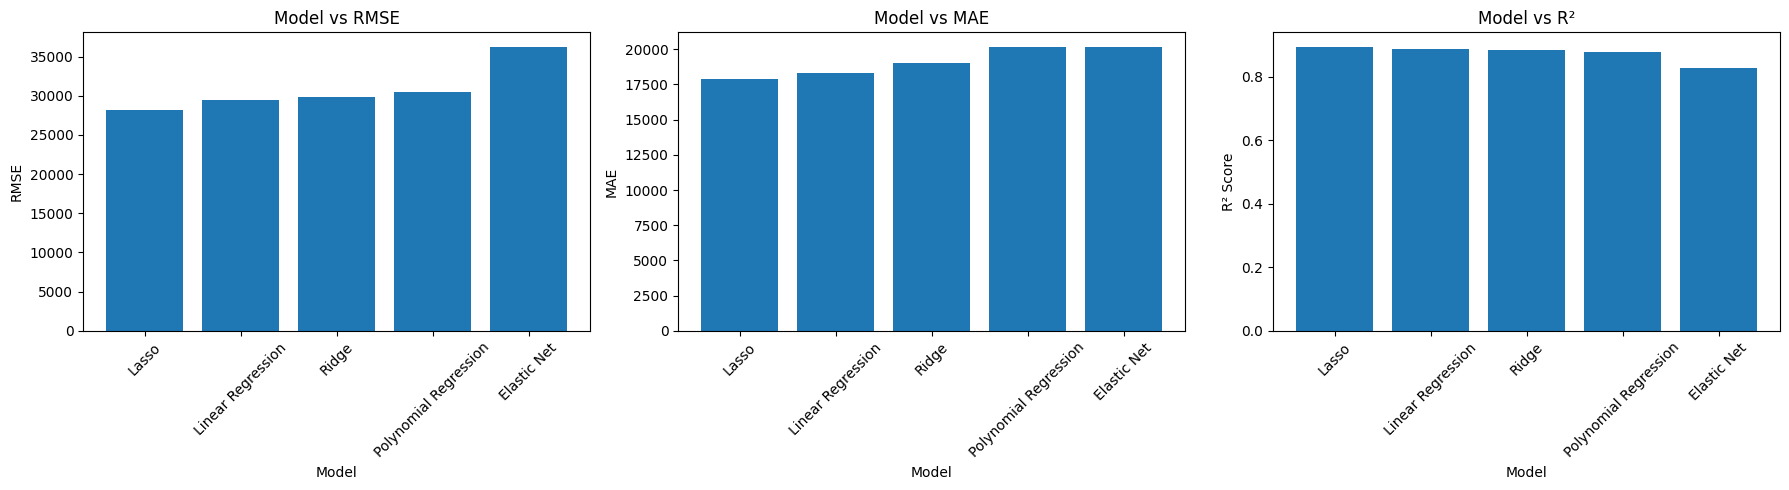

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# RMSE
axes[0].bar(results["Model"], results["RMSE"])
axes[0].set_title("Model vs RMSE")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis="x", rotation=45)

# MAE
axes[1].bar(results["Model"], results["MAE"])
axes[1].set_title("Model vs MAE")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("MAE")
axes[1].tick_params(axis="x", rotation=45)

# R²
axes[2].bar(results["Model"], results["R2"])
axes[2].set_title("Model vs R²")
axes[2].set_xlabel("Model")
axes[2].set_ylabel("R² Score")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import cross_val_score

def cross_validate_models(models, X, y):

    cv_results = []

    for name, model in models.items():

        scores = cross_val_score(
            model,
            X,
            y,
            cv=5,
            scoring="neg_root_mean_squared_error"
        )

        cv_results.append({
            "Model": name,
            "CV RMSE": -scores.mean(),
            "CV Std": scores.std()
        })

    return pd.DataFrame(cv_results).sort_values("CV RMSE")

In [18]:
cv_results = cross_validate_models(models, X, y)

cv_results

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 19657347167.44153, tolerance: 759214014.2531197
  model = cd_fast.sparse_enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 10182125742.205322, tolerance: 699031751.5199751
  model = cd_fast.sparse_enet_coordinate_descent(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations. Duality gap: 9898736510.064148, tolerance: 724930391.3116124
  model = cd_fast.sparse_enet_coordinate_descent(


,Model,CV RMSE,CV Std
4,Polynomial Regression,31798.933811,7685.477995
1,Ridge,32225.515239,7775.346722
3,Elastic Net,33940.752019,7037.410850
2,Lasso,34848.958915,9023.798978
0,Linear Regression,35489.942842,8340.850096


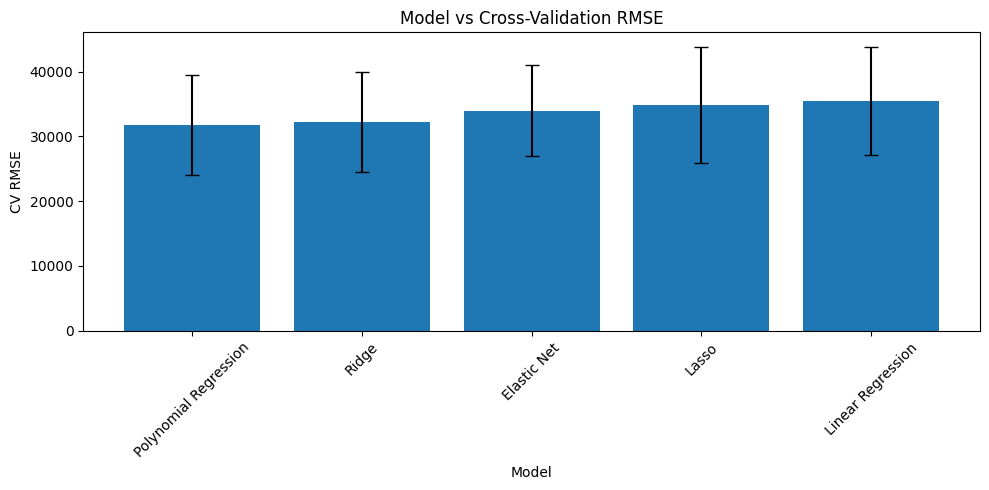

In [19]:
plt.figure(figsize=(10, 5))

plt.bar(
    cv_results["Model"],
    cv_results["CV RMSE"],
    yerr=cv_results["CV Std"],
    capsize=5
)

plt.title("Model vs Cross-Validation RMSE")
plt.xlabel("Model")
plt.ylabel("CV RMSE")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [20]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Ridge": {
        "model__alpha": [0.01, 0.1, 1, 10, 50, 100, 200]
    },

    "Lasso": {
        "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1]
    },

    "Elastic Net": {
        "model__alpha": [0.0001, 0.001, 0.01, 0.1, 1],
        "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]
    }
}

tuned_models = {}
tuning_results = []

for name in ["Ridge", "Lasso", "Elastic Net"]:

    grid = GridSearchCV(
        models[name],
        param_grids[name],
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    tuned_models[name] = grid.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best RMSE": -grid.best_score_,
        "Best Parameters": grid.best_params_
    })

tuning_results = pd.DataFrame(tuning_results)

tuning_results

,Model,Best RMSE,Best Parameters
0,Ridge,32585.456981,{'model__alpha': 10}
1,Lasso,35758.882501,{'model__alpha': 1}
2,Elastic Net,32541.274075,"{'model__alpha': 0.1, 'model__l1_ratio': 0.7}"


In [22]:
poly_grid = GridSearchCV(
    polynomial_model,
    {
        "model__alpha": [1, 10, 50, 100]
    },
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

poly_grid.fit(X_train, y_train)

print("Best RMSE:", -poly_grid.best_score_)
print("Best Parameters:", poly_grid.best_params_)

tuned_models["Polynomial Regression"] = poly_grid.best_estimator_

Best RMSE: 34102.03648923138
Best Parameters: {'model__alpha': 100}


In [24]:
final_models = {
    "Ridge": tuned_models["Ridge"],
    "Lasso": tuned_models["Lasso"],
    "Elastic Net": tuned_models["Elastic Net"],
    "Polynomial Regression": tuned_models["Polynomial Regression"],
    "Linear Regression": models["Linear Regression"]
}

final_results = []

for name, model in final_models.items():

    predictions = model.predict(X_val)

    final_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "R2": r2_score(y_val, predictions)
    })

final_results = (
    pd.DataFrame(final_results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

final_results

,Model,MAE,RMSE,R2
0,Polynomial Regression,17577.704274,28026.630007,0.897593
1,Lasso,17917.289289,28238.394539,0.896040
2,Linear Regression,18284.677599,29476.184616,0.886726
3,Ridge,19021.273763,30655.232540,0.877483
4,Elastic Net,18641.964236,31423.298157,0.871267


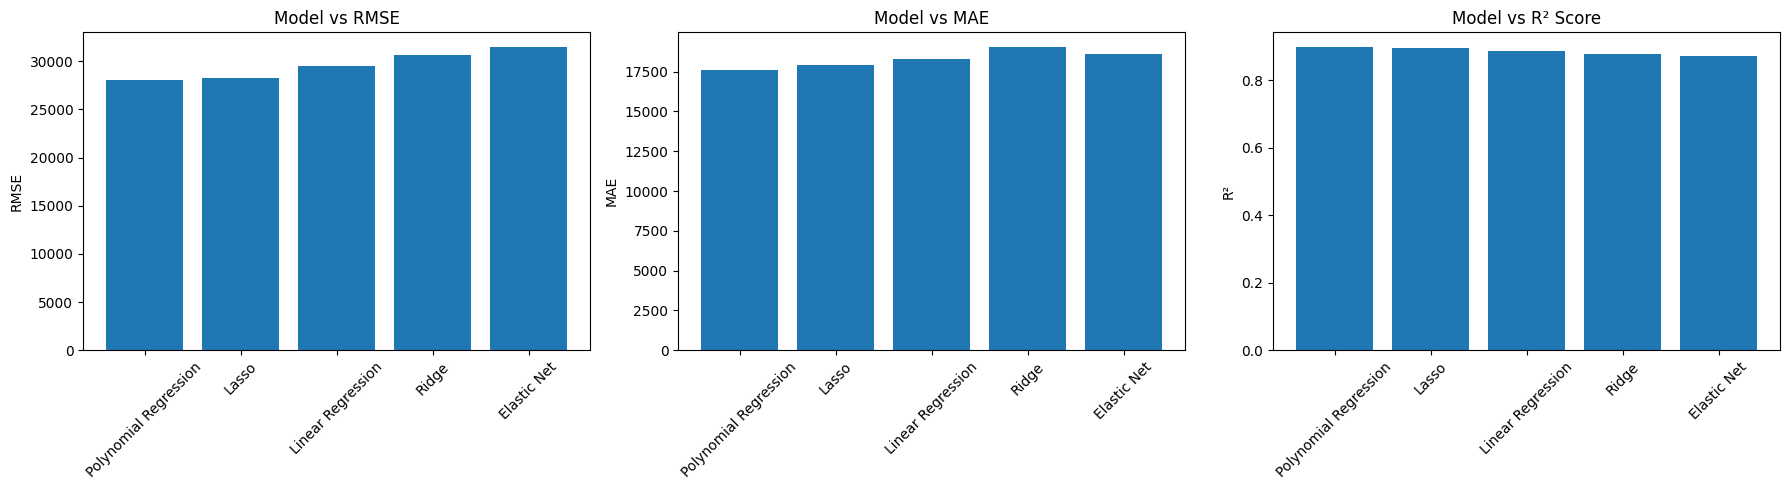

In [25]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# RMSE
axes[0].bar(final_results["Model"], final_results["RMSE"])
axes[0].set_title("Model vs RMSE")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis="x", rotation=45)

# MAE
axes[1].bar(final_results["Model"], final_results["MAE"])
axes[1].set_title("Model vs MAE")
axes[1].set_ylabel("MAE")
axes[1].tick_params(axis="x", rotation=45)

# R2
axes[2].bar(final_results["Model"], final_results["R2"])
axes[2].set_title("Model vs R² Score")
axes[2].set_ylabel("R²")
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [26]:
import os
import joblib

os.makedirs("models", exist_ok=True)

for name, model in final_models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, f"models/{filename}")

print("All models saved successfully.")

All models saved successfully.


In [27]:
os.listdir("models")

['lasso.pkl',
 'polynomial_regression.pkl',
 'elastic_net.pkl',
 'ridge.pkl',
 'linear_regression.pkl']

In [28]:
import joblib

model = joblib.load("models/lasso.pkl")

prediction = model.predict(X_val.iloc[:1])

print("Predicted Price:", prediction[0])
print("Actual Price:", y_val.iloc[0])

Predicted Price: 157482.04816598978
Actual Price: 154500


In [29]:
def predict_house_price(model_name, data):

    model = joblib.load(f"models/{model_name}.pkl")
    prediction = model.predict(data)

    return prediction[0]

In [30]:
price = predict_house_price("lasso", X_val.iloc[:1])

print("Predicted Price:", price)

Predicted Price: 157482.04816598978


In [31]:
import joblib

joblib.dump(X.columns.tolist(), "models/features.pkl")

print("Feature schema saved:", len(X.columns))

Feature schema saved: 80


In [32]:
!pip install flask flask-cors

In [44]:
import shutil

shutil.make_archive("house_price_models", "zip", "models")
print("ZIP created")

ZIP created


In [45]:
from google.colab import files

files.download("house_price_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>